# Proyek Analisis Data: Tren & Prediksi Angka Putus Sekolah di Bandar Lampung

**Dataset:**
Dataset diperoleh dari website opendata.lampungprov.go.id

**Tujuan Proyek:**  
Menganalisis faktor-faktor yang mempengaruhi angka putus sekolah di Bandar Lampung berdasarkan jenjang pendidikan, tipe sekolah, dan wilayah (kecamatan), serta membangun model regresi sederhana untuk memproyeksikan tren ke depannya.

**Pertanyaan Bisnis:**
1. Bagaimana tren jumlah anak putus sekolah di Bandar Lampung dari tahun ke tahun?
2. Jenjang pendidikan apa yang menyumbang angka putus sekolah tertinggi?
3. Kecamatan mana saja yang menjadi *hotspot* (Top 5 wilayah dengan kasus terbanyak)?
4. Bagaimana perbandingan angka putus sekolah antara sekolah Negeri vs Swasta?
5. Bagaimana proyeksi tren total anak putus sekolah di masa depan (tahun 2025) berdasarkan data historis?

## 1. Import Library
Mengimpor seluruh pustaka Python yang dibutuhkan untuk manipulasi data, visualisasi, dan pemodelan *machine learning*.

In [117]:
import os
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

## 2. Pengumpulan & Inspeksi Data (Data Gathering & Understanding)
Langkah pertama adalah mengunggah dataset **mentah** (`dataset_all.csv`) ke dalam Google Colab. Setelah data berhasil dimuat, kita akan melakukan inspeksi awal untuk melihat isi kolom, tipe data, serta mendeteksi apakah ada nilai yang hilang (*missing values*).

Selain itu, pada tahap ini kita juga melakukan **penilaian kualitas data (*data assessing*)**: memeriksa data duplikat dan memastikan setiap baris benar-benar mewakili kasus yang berbeda, agar angka yang dihitung nanti tidak terhitung ganda.

In [118]:
# Di Google Colab akan memunculkan tombol 'Choose Files'; jika dijalankan lokal, file dibaca langsung dari folder yang sama.
file_path = 'dataset_all.csv'
try:
    from google.colab import files
    if not os.path.exists(file_path):
        uploaded = files.upload()
        # Membaca nama file yang baru saja diunggah secara dinamis
        file_path = list(uploaded.keys())[0]
except ImportError:
    pass

# Memuat data ke dalam DataFrame
dataset_all_df = pd.read_csv(file_path)

print("\n--- Cuplikan Data Awal ---")
display(dataset_all_df.head())

print("\n--- Informasi Dataset ---")
dataset_all_df.info()

print("\n--- Pengecekan Missing Values Awal ---")
print(dataset_all_df.isnull().sum())


--- Cuplikan Data Awal ---


,Kecamatan,Jenjang,Tahun,Jumlah,Jenis Kelamin,Tipe Sekolah,Tingkat
0,Kec. Teluk Betung Barat,SD,2021,0,Laki-laki,Negeri,NaN
1,Kec. Teluk Betung Selatan,SD,2021,0,Laki-laki,Negeri,NaN
2,Kec. Panjang,SD,2021,0,Laki-laki,Negeri,NaN
3,Kec. Tanjung Karang Timur,SD,2021,2,Laki-laki,Negeri,NaN
4,Kec. Teluk Betung Utara,SD,2021,2,Laki-laki,Negeri,NaN



--- Informasi Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2744 entries, 0 to 2743
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Kecamatan      2744 non-null   object
 1   Jenjang        2744 non-null   object
 2   Tahun          2744 non-null   int64 
 3   Jumlah         2744 non-null   int64 
 4   Jenis Kelamin  2744 non-null   object
 5   Tipe Sekolah   480 non-null    object
 6   Tingkat        2264 non-null   object
dtypes: int64(2), object(5)
memory usage: 150.2+ KB

--- Pengecekan Missing Values Awal ---
Kecamatan           0
Jenjang             0
Tahun               0
Jumlah              0
Jenis Kelamin       0
Tipe Sekolah     2264
Tingkat           480
dtype: int64


### Assessing Data: Pengecekan Duplikat dan Struktur Data
Hasil inspeksi menunjukkan kolom `Tipe Sekolah` dan `Tingkat` memiliki banyak nilai kosong. Sebelum memutuskan cara menanganinya, kita perlu memahami **mengapa** nilai tersebut kosong, serta memeriksa apakah ada baris duplikat.

In [119]:
print("--- Baris Duplikat Persis ---")
print("Total duplikat:", dataset_all_df.duplicated().sum())
print(dataset_all_df[dataset_all_df.duplicated()].groupby('Jenjang').size().rename('Jumlah Duplikat'))

print("\n--- Struktur Label per Jenjang (kosong ditampilkan sebagai '(kosong)') ---")
struktur = (dataset_all_df.fillna({'Tipe Sekolah': '(kosong)', 'Tingkat': '(kosong)'})
            .groupby(['Jenjang', 'Tipe Sekolah', 'Tingkat'])
            .agg(jumlah_baris=('Jumlah', 'size'), total_jumlah=('Jumlah', 'sum')))
display(struktur)

--- Baris Duplikat Persis ---
Total duplikat: 500
Jenjang
SMK    500
Name: Jumlah Duplikat, dtype: int64

--- Struktur Label per Jenjang (kosong ditampilkan sebagai '(kosong)') ---


jumlah_baris  total_jumlah
Jenjang Tipe Sekolah Tingkat                             
SD      Negeri       (kosong)           160           243
        Swasta       (kosong)           160            30
        Total        (kosong)           160           273
SMA     (kosong)     Total              146            79
                     X                  146            45
                     XI                 146            11
                     XII                146            23
SMK     (kosong)     Total              650            72
                     X                  130             6
                     XI                 130             9
                     XII                130             9
SMP     (kosong)     IX                 160            16
                     Total              160            61
                     VII                160            38
                     VIII               160             7

**Temuan dari proses assessing:**
1. **Nilai kosong bersifat struktural, bukan data hilang.** Jenjang **SD** hanya dirinci berdasarkan `Tipe Sekolah` (Negeri/Swasta), sedangkan **SMP, SMA, SMK** hanya dirinci berdasarkan `Tingkat` kelas. Jadi kolom yang tidak berlaku untuk suatu jenjang otomatis kosong.
2. **Baris `Total` bercampur dengan baris rincian.** Di setiap jenjang terdapat baris `Total` *di samping* baris rincian (Negeri + Swasta + Total, atau kelas + Total). Jika seluruh baris dijumlahkan, setiap kasus akan **terhitung dua kali**.
3. **Seluruh 500 baris duplikat berasal dari jenjang SMK** (khusus baris `Total`).

Temuan nomor 3 perlu diselidiki lebih lanjut agar kita tahu angka SMK mana yang benar.

In [120]:
# Investigasi SMK: membandingkan baris 'Total' dengan rincian X + XI + XII
kunci_wilayah = ['Kecamatan', 'Tahun', 'Jenis Kelamin']
smk_total = dataset_all_df[(dataset_all_df['Jenjang'] == 'SMK') & (dataset_all_df['Tingkat'] == 'Total')]
smk_rinci = dataset_all_df[(dataset_all_df['Jenjang'] == 'SMK') & (dataset_all_df['Tingkat'] != 'Total')]

kombinasi_unik = smk_total.drop_duplicates(kunci_wilayah).shape[0]
print("Baris 'Total' SMK                  :", len(smk_total))
print("Kombinasi unik (kec, tahun, gender):", kombinasi_unik)
print("Rata-rata pengulangan              :", round(len(smk_total) / kombinasi_unik, 1), "kali per kombinasi")
print("Sum 'Total' SMK (mentah)           :", smk_total['Jumlah'].sum())
print("Sum rincian X + XI + XII           :", smk_rinci['Jumlah'].sum())

# Uji: apakah nilai Total (nilai terbesar dari baris yang berulang) = X + XI + XII?
uji_smk = pd.concat([
    smk_total.groupby(kunci_wilayah)['Jumlah'].max().rename('Total (max)'),
    smk_total.drop_duplicates().groupby(kunci_wilayah)['Jumlah'].sum().rename('Total (hapus duplikat saja)'),
    smk_rinci.groupby(kunci_wilayah)['Jumlah'].sum().rename('X+XI+XII')
], axis=1)

print("\nJumlah kombinasi yang diuji            :", len(uji_smk))
print("Selisih bila memakai Total (max)        :", (uji_smk['Total (max)'] != uji_smk['X+XI+XII']).sum())
print("Selisih bila hanya menghapus duplikat   :", (uji_smk['Total (hapus duplikat saja)'] != uji_smk['X+XI+XII']).sum())

Baris 'Total' SMK                  : 650
Kombinasi unik (kec, tahun, gender): 130
Rata-rata pengulangan              : 5.0 kali per kombinasi
Sum 'Total' SMK (mentah)           : 72
Sum rincian X + XI + XII           : 24

Jumlah kombinasi yang diuji            : 130
Selisih bila memakai Total (max)        : 0
Selisih bila hanya menghapus duplikat   : 1


**Kesimpulan assessing SMK:** baris `Total` SMK adalah salinan yang berulang (rata-rata 5×) dari satu nilai yang sama, sehingga sum mentahnya (72) jauh lebih besar dari rincian per kelas (24). Nilai `Total` yang sebenarnya cocok **100%** dengan penjumlahan X + XI + XII, sehingga untuk SMK kita memakai **rincian per kelas**.

Dengan demikian, aturan pembersihan yang akan diterapkan: **gunakan baris rincian saja** (SD: Negeri + Swasta, SMP/SMA/SMK: per kelas) dan buang seluruh baris `Total`.

## 3. Pembersihan Data (Data Cleaning & Wrangling)
Berdasarkan hasil inspeksi di tahap sebelumnya, kita mengetahui bahwa dataset memiliki kolom `Tipe Sekolah` dan `Tingkat` yang berisi banyak nilai kosong (*missing values*), serta baris `Total` yang menyebabkan perhitungan ganda.

Jika kita menghapus baris yang kosong tersebut, kita akan kehilangan data jumlah anak putus sekolah secara keseluruhan. Oleh karena itu, langkah pembersihan yang akan kita lakukan adalah:
1. Mengimputasi (mengisi) nilai kosong pada kolom `Tipe Sekolah` dan `Tingkat` dengan label **"Unknown"** (tidak berlaku untuk jenjang tersebut).
2. Memastikan tipe data pada kolom `Tahun` dan `Jumlah` sudah sesuai (Integer) agar bisa diolah untuk visualisasi dan pemodelan.
3. Merapikan teks (spasi berlebih) dan menyeragamkan penulisan nama `Kecamatan` (menghapus awalan "Kec.").
4. Menghapus baris `Total` (dan seluruh duplikatnya) dan hanya menyimpan baris rincian, agar **tidak ada perhitungan ganda**.
5. Memvalidasi hasil pembersihan terhadap total asli yang ada di data.
6. Menambahkan kolom bantu `Kelas` (Kelas 07 ... Kelas 12) agar urutan kelas benar saat divisualisasikan.

In [121]:
# 1. Imputasi Missing Values dengan 'Unknown'
dataset_all_df['Tipe Sekolah'] = dataset_all_df['Tipe Sekolah'].fillna('Unknown')
dataset_all_df['Tingkat'] = dataset_all_df['Tingkat'].fillna('Unknown')

# 2. Konversi tipe data
dataset_all_df['Tahun'] = dataset_all_df['Tahun'].astype(int)
dataset_all_df['Jumlah'] = dataset_all_df['Jumlah'].astype(int)

# 3. Rapikan teks & seragamkan nama Kecamatan (contoh: 'Kec. Tanjung Senang' -> 'Tanjung Senang')
for kolom in ['Kecamatan', 'Jenjang', 'Jenis Kelamin', 'Tipe Sekolah', 'Tingkat']:
    dataset_all_df[kolom] = dataset_all_df[kolom].astype(str).str.strip()
dataset_all_df['Kecamatan'] = dataset_all_df['Kecamatan'].str.replace(r'^Kec\.\s*', '', regex=True).str.title()

print("Pembersihan tahap 1-3 selesai! Pengecekan Missing Values Akhir:\n")
print(dataset_all_df.isnull().sum())

Pembersihan tahap 1-3 selesai! Pengecekan Missing Values Akhir:

Kecamatan        0
Jenjang          0
Tahun            0
Jumlah           0
Jenis Kelamin    0
Tipe Sekolah     0
Tingkat          0
dtype: int64


In [122]:
# 4. Hanya simpan baris rincian (buang baris 'Total' dan duplikatnya)
#    - SD            : baris Negeri & Swasta  (kolom Tingkat = 'Unknown')
#    - SMP/SMA/SMK   : baris per kelas        (kolom Tipe Sekolah = 'Unknown')
df_mentah = dataset_all_df.copy()   # disimpan untuk validasi

is_sd_rinci  = (df_mentah['Jenjang'] == 'SD')  & (df_mentah['Tipe Sekolah'] != 'Total')
is_non_rinci = (df_mentah['Jenjang'] != 'SD')  & (df_mentah['Tingkat'] != 'Total')
dataset_all_df = df_mentah[is_sd_rinci | is_non_rinci].copy()

# Pastikan satu baris = satu kombinasi unik (tidak ada duplikat tersisa)
kunci = ['Tahun', 'Kecamatan', 'Jenjang', 'Jenis Kelamin', 'Tipe Sekolah', 'Tingkat']
dataset_all_df = dataset_all_df.sort_values(kunci).reset_index(drop=True)

# Kolom bantu 'Kelas' berurutan (agar urutan kelas benar di grafik/dashboard: Kelas 07 ... Kelas 12)
peta_kelas = {'VII': 'Kelas 07', 'VIII': 'Kelas 08', 'IX': 'Kelas 09', 'X': 'Kelas 10', 'XI': 'Kelas 11', 'XII': 'Kelas 12'}
dataset_all_df['Kelas'] = dataset_all_df['Tingkat'].map(peta_kelas).fillna('Unknown')
assert dataset_all_df.duplicated(kunci).sum() == 0, "Masih ada baris ganda!"

print("Ukuran data sebelum :", df_mentah.shape)
print("Ukuran data sesudah :", dataset_all_df.shape)
display(dataset_all_df.head())

Ukuran data sebelum : (2744, 7)
Ukuran data sesudah : (1628, 8)


,Kecamatan,Jenjang,Tahun,Jumlah,Jenis Kelamin,Tipe Sekolah,Tingkat,Kelas
0,Bumi Waras,SD,2021,1,Laki-laki,Negeri,Unknown,Unknown
1,Bumi Waras,SD,2021,0,Laki-laki,Swasta,Unknown,Unknown
2,Bumi Waras,SD,2021,1,Perempuan,Negeri,Unknown,Unknown
3,Bumi Waras,SD,2021,0,Perempuan,Swasta,Unknown,Unknown
4,Bumi Waras,SMA,2021,0,Laki-laki,Unknown,X,Kelas 10


In [123]:
# 5. Validasi: total hasil bersih harus sama dengan baris 'Total' asli (untuk jenjang yang datanya konsisten)
total_asli = {
    'SD' : df_mentah[(df_mentah['Jenjang'] == 'SD')  & (df_mentah['Tipe Sekolah'] == 'Total')]['Jumlah'].sum(),
    'SMP': df_mentah[(df_mentah['Jenjang'] == 'SMP') & (df_mentah['Tingkat'] == 'Total')]['Jumlah'].sum(),
    'SMA': df_mentah[(df_mentah['Jenjang'] == 'SMA') & (df_mentah['Tingkat'] == 'Total')]['Jumlah'].sum(),
}
validasi = pd.DataFrame({
    'Hasil Bersih': dataset_all_df.groupby('Jenjang')['Jumlah'].sum(),
    'Total Asli di Data': pd.Series(total_asli)
})
validasi['Status'] = np.where(validasi['Total Asli di Data'].isna(), 'SMK: memakai rincian (lihat assessing)',
                       np.where(validasi['Hasil Bersih'] == validasi['Total Asli di Data'], 'Cocok', 'Berbeda'))
display(validasi)

print("Total kasus (setelah dibersihkan)            :", dataset_all_df['Jumlah'].sum(), "anak")
print("Pembanding: sum seluruh baris data mentah    :", df_mentah['Jumlah'].sum(), "anak (terhitung ganda)")

print("\nJumlah kecamatan yang tercatat per jenjang-tahun:")
display(dataset_all_df.groupby(['Jenjang', 'Tahun'])['Kecamatan'].nunique().unstack())

,Hasil Bersih,Total Asli di Data,Status
SD,273,273.0,Cocok
SMA,79,79.0,Cocok
SMK,24,NaN,SMK: memakai rincian (lihat assessing)
SMP,61,61.0,Cocok


Total kasus (setelah dibersihkan)            : 437 anak
Pembanding: sum seluruh baris data mentah    : 922 anak (terhitung ganda)

Jumlah kecamatan yang tercatat per jenjang-tahun:


Tahun,2021,2022,2023,2024
Jenjang,,,,
SD,20,20,20,20
SMA,18,18,18,19
SMK,17,16,16,16
SMP,20,20,20,20


> **Catatan kelengkapan data:** SMA tercatat di 18–19 kecamatan dan SMK di 16–17 kecamatan (bukan 20). Kecamatan yang tidak muncul diasumsikan tidak memiliki sekolah pada jenjang tersebut, bukan data yang hilang.

In [124]:
# Menyimpan hasil cleaning ke file baru (dipakai sebagai sumber data utama di Looker Studio)
output_filename = 'dataset_all_clean.csv'
dataset_all_df.to_csv(output_filename, index=False)
print(f"\nFile bersih berhasil disimpan sebagai '{output_filename}'!")


File bersih berhasil disimpan sebagai 'dataset_all_clean.csv'!


## 4. Exploratory Data Analysis (EDA)
Pada tahap ini, kita akan mengeksplorasi data yang sudah bersih untuk menjawab pertanyaan-pertanyaan bisnis yang telah didefinisikan di awal menggunakan visualisasi data.

### Pertanyaan 1: Bagaimana tren jumlah anak putus sekolah di Bandar Lampung dari tahun ke tahun?
Kita akan melihat pergerakan total anak putus sekolah dari tahun 2021 hingga 2024 menggunakan *line chart* untuk mendeteksi apakah ada lonjakan atau penurunan pada tahun-tahun tertentu.

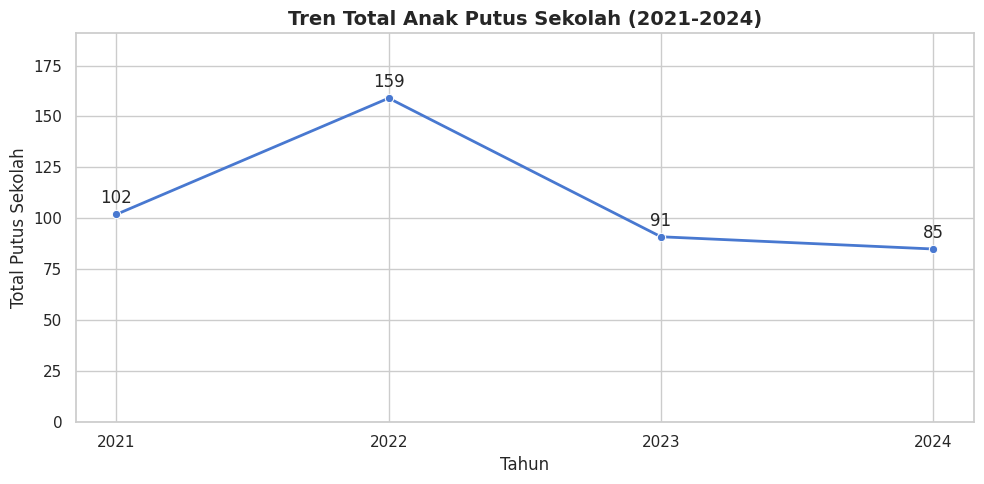

,Tahun,Jumlah
0,2021,102
1,2022,159
2,2023,91
3,2024,85


In [125]:
# Menghitung total putus sekolah per tahun
tren_tahunan = dataset_all_df.groupby('Tahun')['Jumlah'].sum().reset_index()

# Membuat visualisasi
plt.figure(figsize=(10, 5))
sns.lineplot(data=tren_tahunan, x='Tahun', y='Jumlah', marker='o', color='b', linewidth=2)
for _, baris in tren_tahunan.iterrows():
    plt.annotate(int(baris['Jumlah']), (baris['Tahun'], baris['Jumlah']), textcoords='offset points', xytext=(0, 8), ha='center')
plt.title('Tren Total Anak Putus Sekolah (2021-2024)', fontsize=14, fontweight='bold')
plt.xlabel('Tahun')
plt.ylabel('Total Putus Sekolah')
plt.xticks(tren_tahunan['Tahun']) # Memastikan sumbu X hanya menampilkan angka tahun yang ada
plt.ylim(0, tren_tahunan['Jumlah'].max() * 1.2)
plt.tight_layout()
plt.show()

display(tren_tahunan)

**Insight:** Jumlah anak putus sekolah melonjak tajam pada tahun 2022 (puncak), kemudian turun pada 2023 dan 2024.

### Pertanyaan 2: Jenjang pendidikan apa yang menyumbang angka putus sekolah tertinggi?
Selanjutnya, kita akan membandingkan jumlah anak putus sekolah berdasarkan jenjang pendidikannya (SD, SMP, SMA, SMK) untuk mengetahui di level mana kerentanan tertinggi terjadi.

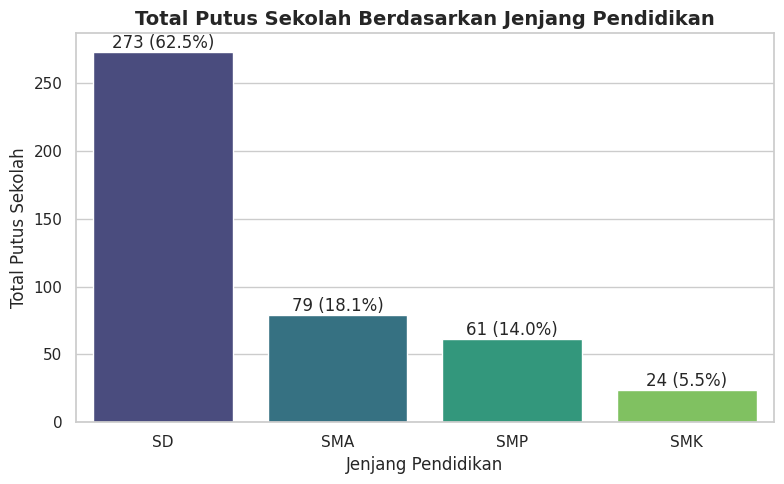

Jenjang,SD,SMP,SMA,SMK
Tahun,,,,
2021,42,33,20,7
2022,100,11,43,5
2023,56,14,12,9
2024,75,3,4,3


In [126]:
# Menghitung total putus sekolah per jenjang dan mengurutkannya dari yang terbesar
tren_jenjang = dataset_all_df.groupby('Jenjang')['Jumlah'].sum().sort_values(ascending=False).reset_index()
tren_jenjang['Persen'] = (tren_jenjang['Jumlah'] / tren_jenjang['Jumlah'].sum() * 100).round(1)

# Membuat visualisasi
plt.figure(figsize=(8, 5))
sns.barplot(data=tren_jenjang, x='Jenjang', y='Jumlah', hue='Jenjang', palette='viridis', legend=False)
for i, baris in tren_jenjang.iterrows():
    plt.text(i, baris['Jumlah'], f"{baris['Jumlah']} ({baris['Persen']}%)", ha='center', va='bottom')
plt.title('Total Putus Sekolah Berdasarkan Jenjang Pendidikan', fontsize=14, fontweight='bold')
plt.xlabel('Jenjang Pendidikan')
plt.ylabel('Total Putus Sekolah')
plt.tight_layout()
plt.show()

# Rincian per tahun untuk melihat pergeseran antar jenjang
pivot_jenjang = dataset_all_df.pivot_table(index='Tahun', columns='Jenjang', values='Jumlah', aggfunc='sum')[['SD', 'SMP', 'SMA', 'SMK']]
display(pivot_jenjang)

**Insight:** Jenjang **SD** menyumbang kasus terbanyak, lebih dari separuh seluruh kasus. SD juga menjadi satu-satunya jenjang yang angkanya naik kembali pada 2024, sedangkan SMP, SMA, dan SMK cenderung turun.

### Pertanyaan 3: Kecamatan mana saja yang menjadi *hotspot* (Top 5 wilayah dengan kasus terbanyak)?
Untuk membantu pemerintah daerah memfokuskan intervensi, kita akan memetakan 5 kecamatan yang memiliki akumulasi angka putus sekolah tertinggi. Kita gunakan *horizontal bar chart* agar nama kecamatan mudah dibaca.

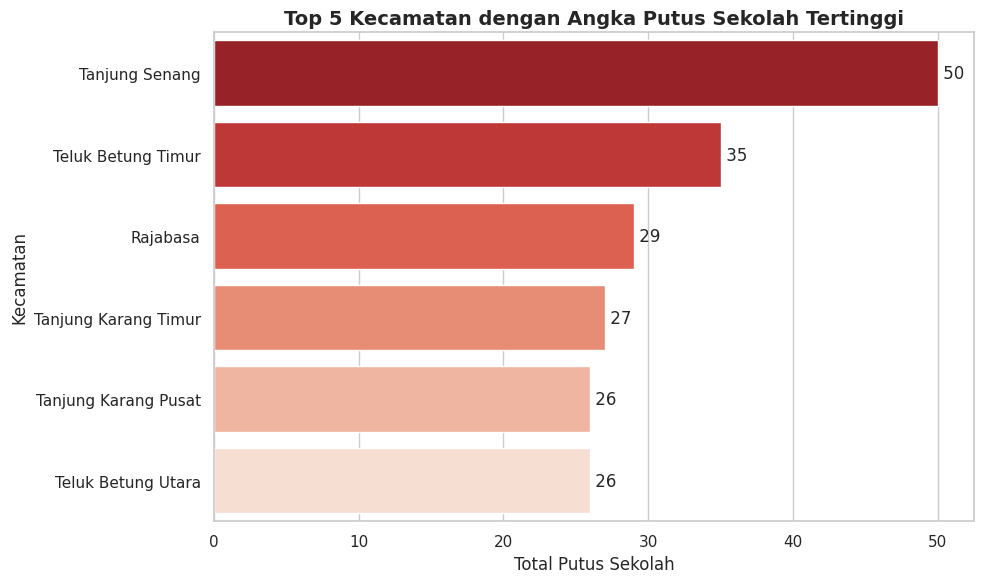

Jenjang,SD,SMA,SMK,SMP
Kecamatan,,,,
Tanjung Senang,14,32,0,4
Teluk Betung Timur,35,0,0,0
Rajabasa,28,1,0,0
Tanjung Karang Timur,11,16,0,0
Tanjung Karang Pusat,14,1,2,9
Teluk Betung Utara,15,4,5,2


In [127]:
# Mengambil 5 kecamatan dengan jumlah kasus tertinggi (keep='all' agar kecamatan dengan nilai imbang tidak terpotong)
hotspot_kecamatan = (dataset_all_df.groupby('Kecamatan')['Jumlah'].sum()
                     .nlargest(5, keep='all').reset_index())

# Membuat visualisasi
plt.figure(figsize=(10, 6))
sns.barplot(data=hotspot_kecamatan, y='Kecamatan', x='Jumlah', hue='Kecamatan', palette='Reds_r', legend=False)
for i, nilai in enumerate(hotspot_kecamatan['Jumlah']):
    plt.text(nilai, i, f' {nilai}', va='center')
plt.title('Top 5 Kecamatan dengan Angka Putus Sekolah Tertinggi', fontsize=14, fontweight='bold')
plt.xlabel('Total Putus Sekolah')
plt.ylabel('Kecamatan')
plt.tight_layout()
plt.show()

# Rincian jenjang di kecamatan hotspot
display(dataset_all_df[dataset_all_df['Kecamatan'].isin(hotspot_kecamatan['Kecamatan'])]
        .pivot_table(index='Kecamatan', columns='Jenjang', values='Jumlah', aggfunc='sum')
        .loc[hotspot_kecamatan['Kecamatan']])

**Insight:** **Tanjung Senang** adalah *hotspot* kumulatif (2021-2024) dengan selisih yang cukup jauh dari kecamatan lain, dan kasusnya didominasi jenjang SMA. Peringkat ke-5 dimiliki dua kecamatan dengan nilai yang sama (imbang), sehingga keduanya ditampilkan.

> **Catatan penting:** peringkat kumulatif bisa menyesatkan. Pada bagian *Eksplorasi Lanjutan* di bawah terlihat bahwa kasus Tanjung Senang sebagian besar berasal dari satu tahun saja (2022).

### Pertanyaan 4: Bagaimana perbandingan angka putus sekolah antara sekolah Negeri vs Swasta?
Setelah proses pembersihan, kita ketahui data `Tipe Sekolah` (Negeri vs Swasta) **hanya tersedia untuk jenjang SD**, sedangkan jenjang lain berlabel "Unknown". Maka perbandingan ini hanya valid untuk SD, dan kita memfilter label "Unknown" agar perbandingan akurat.

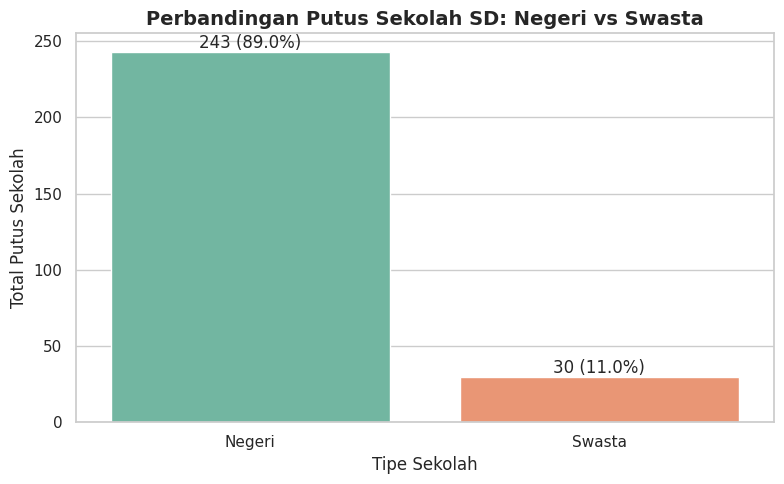

In [128]:
# Memfilter data untuk menghilangkan label 'Unknown' agar perbandingan akurat
tipe_sekolah = dataset_all_df[dataset_all_df['Tipe Sekolah'] != 'Unknown']

# Menghitung total berdasarkan tipe sekolah
perbandingan_tipe = tipe_sekolah.groupby('Tipe Sekolah')['Jumlah'].sum().reset_index()
perbandingan_tipe['Persen'] = (perbandingan_tipe['Jumlah'] / perbandingan_tipe['Jumlah'].sum() * 100).round(1)

# Membuat visualisasi
plt.figure(figsize=(8, 5))
sns.barplot(data=perbandingan_tipe, x='Tipe Sekolah', y='Jumlah', hue='Tipe Sekolah', palette='Set2', legend=False)
for i, baris in perbandingan_tipe.iterrows():
    plt.text(i, baris['Jumlah'], f"{baris['Jumlah']} ({baris['Persen']}%)", ha='center', va='bottom')
plt.title('Perbandingan Putus Sekolah SD: Negeri vs Swasta', fontsize=14, fontweight='bold')
plt.xlabel('Tipe Sekolah')
plt.ylabel('Total Putus Sekolah')
plt.tight_layout()
plt.show()

**Insight:** Pada jenjang SD, kasus putus sekolah jauh lebih banyak terjadi di sekolah **Negeri**. Namun perlu diingat bahwa data ini belum dibandingkan dengan jumlah total siswa di masing-masing tipe sekolah, sehingga belum bisa disimpulkan bahwa sekolah Negeri lebih berisiko secara proporsional.

## Eksplorasi Lanjutan (Deep Dive)
Kelima pertanyaan di atas dijawab dengan angka total. Pada bagian ini kita menggali lebih dalam untuk mencari **penyebab** di balik angka tersebut, karena total yang turun bisa menyembunyikan lonjakan di satu wilayah.

1. Apakah hotspot kumulatif sama dengan hotspot terbaru?
2. Apa yang menyebabkan kenaikan kasus SD pada 2024?
3. Siapa yang putus sekolah: bagaimana pola jenis kelamin per jenjang?
4. Pada kelas berapa anak paling rawan putus sekolah?
5. Seberapa terkonsentrasi kasusnya, dan kecamatan mana yang perlu diprioritaskan?

### E1: Apakah hotspot kumulatif sama dengan hotspot terbaru?
Peringkat kumulatif 2021-2024 menggabungkan semua tahun, sehingga lonjakan satu tahun bisa membuat sebuah kecamatan tampak "selalu bermasalah". Kita bandingkan dengan peta panas kecamatan × tahun.

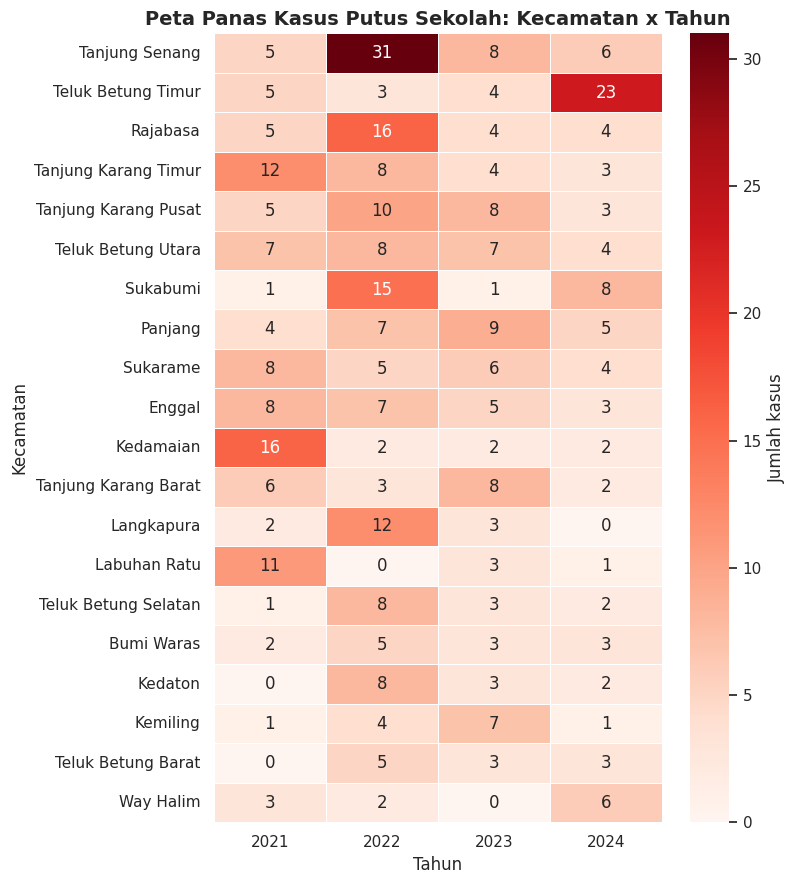

Hotspot kumulatif 2021-2024 : Tanjung Senang (50 kasus)
   Kasus per tahun          : {2021: 5, 2022: 31, 2023: 8, 2024: 6}
Hotspot terbaru (2024)      : Teluk Betung Timur (23 kasus = 27.1% dari seluruh kasus 2024)
   Kasus per tahun          : {2021: 5, 2022: 3, 2023: 4, 2024: 23}

Kecamatan turun 2023->2024: 13 | naik: 3 | tetap: 4


In [129]:
# Rekap kecamatan x tahun (seluruh 20 kecamatan)
kec_tahun = (dataset_all_df.pivot_table(index='Kecamatan', columns='Tahun', values='Jumlah', aggfunc='sum')
             .fillna(0).astype(int))
kec_tahun['Total'] = kec_tahun[[2021, 2022, 2023, 2024]].sum(axis=1)
urutan_kec = kec_tahun['Total'].sort_values(ascending=False).index

plt.figure(figsize=(8, 9))
sns.heatmap(kec_tahun.loc[urutan_kec, [2021, 2022, 2023, 2024]], annot=True, fmt='d', cmap='Reds',
            linewidths=0.5, cbar_kws={'label': 'Jumlah kasus'})
plt.title('Peta Panas Kasus Putus Sekolah: Kecamatan x Tahun', fontsize=14, fontweight='bold')
plt.xlabel('Tahun')
plt.ylabel('Kecamatan')
plt.tight_layout()
plt.show()

hotspot_kumulatif = kec_tahun['Total'].idxmax()
hotspot_2024 = kec_tahun[2024].idxmax()
total_2024 = kec_tahun[2024].sum()
print(f"Hotspot kumulatif 2021-2024 : {hotspot_kumulatif} ({kec_tahun.loc[hotspot_kumulatif, 'Total']} kasus)")
print("   Kasus per tahun          :", kec_tahun.loc[hotspot_kumulatif, [2021, 2022, 2023, 2024]].to_dict())
print(f"Hotspot terbaru (2024)      : {hotspot_2024} ({kec_tahun.loc[hotspot_2024, 2024]} kasus = "
      f"{kec_tahun.loc[hotspot_2024, 2024] / total_2024 * 100:.1f}% dari seluruh kasus 2024)")
print("   Kasus per tahun          :", kec_tahun.loc[hotspot_2024, [2021, 2022, 2023, 2024]].to_dict())
print(f"\nKecamatan turun 2023->2024: {(kec_tahun[2024] < kec_tahun[2023]).sum()} | "
      f"naik: {(kec_tahun[2024] > kec_tahun[2023]).sum()} | tetap: {(kec_tahun[2024] == kec_tahun[2023]).sum()}")

**Insight:**
- **Tanjung Senang** (hotspot kumulatif, 50 kasus) ternyata didominasi **lonjakan satu tahun**: 31 kasus terjadi pada 2022 (26 di antaranya SMA), lalu kembali ke 8 (2023) dan 6 (2024). Ini bukan masalah yang terus-menerus.
- **Teluk Betung Timur** hanya 4-5 kasus per tahun sampai 2023, lalu melonjak menjadi **23 kasus pada 2024** (27% dari seluruh kasus tahun itu). Inilah hotspot terbaru.
- Secara umum kondisi membaik: **13 dari 20 kecamatan turun** pada 2024, 4 tetap, dan hanya 3 yang naik (Teluk Betung Timur, Sukabumi, Way Halim).

### E2: Apa yang menyebabkan kenaikan kasus SD pada 2024?
SD naik dari 56 (2023) menjadi 75 (2024). Kita uraikan perubahan tersebut per kecamatan untuk melihat apakah kenaikannya merata atau terpusat.

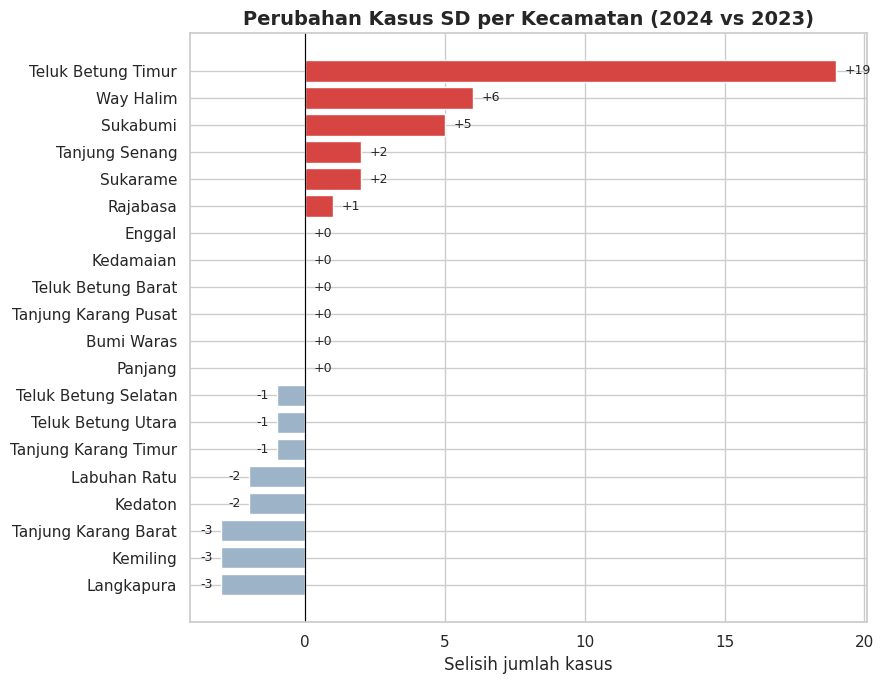

Kenaikan bersih kasus SD (2023 -> 2024)   : +19 anak
Kenaikan di Teluk Betung Timur            : +19 anak
SD tanpa Teluk Betung Timur               : 2023 = 52, 2024 = 52


In [130]:
sd_kecamatan = (dataset_all_df[dataset_all_df['Jenjang'] == 'SD']
                .pivot_table(index='Kecamatan', columns='Tahun', values='Jumlah', aggfunc='sum').fillna(0))
sd_kecamatan['Perubahan'] = (sd_kecamatan[2024] - sd_kecamatan[2023]).astype(int)
kontribusi_sd = sd_kecamatan['Perubahan'].sort_values(ascending=True)

plt.figure(figsize=(9, 7))
warna = ['#D64541' if v > 0 else '#9DB4C8' for v in kontribusi_sd.values]
plt.barh(kontribusi_sd.index, kontribusi_sd.values, color=warna)
for i, v in enumerate(kontribusi_sd.values):
    plt.text(v + (0.3 if v >= 0 else -0.3), i, f"{v:+d}", va='center', ha='left' if v >= 0 else 'right', fontsize=9)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Perubahan Kasus SD per Kecamatan (2024 vs 2023)', fontsize=14, fontweight='bold')
plt.xlabel('Selisih jumlah kasus')
plt.tight_layout()
plt.show()

kenaikan_sd = int(sd_kecamatan[2024].sum() - sd_kecamatan[2023].sum())
tbt = sd_kecamatan.loc['Teluk Betung Timur']
print(f"Kenaikan bersih kasus SD (2023 -> 2024)   : {kenaikan_sd:+d} anak")
print(f"Kenaikan di Teluk Betung Timur            : {int(tbt['Perubahan']):+d} anak")
print(f"SD tanpa Teluk Betung Timur               : 2023 = {int(sd_kecamatan[2023].sum() - tbt[2023])}, "
      f"2024 = {int(sd_kecamatan[2024].sum() - tbt[2024])}")

**Insight:** Kenaikan bersih kasus SD (+19) **sama persis dengan kenaikan di Teluk Betung Timur (+19)**. Tanpa kecamatan ini, kasus SD tidak berubah (52 pada 2023 dan 52 pada 2024). Jadi "SD makin bermasalah" lebih tepat dibaca sebagai **lonjakan lokal di satu kecamatan**, bukan kenaikan merata di seluruh kota. Penyebab di lapangan perlu ditelusuri lebih lanjut.

### E3: Siapa yang putus sekolah? Pola jenis kelamin per jenjang

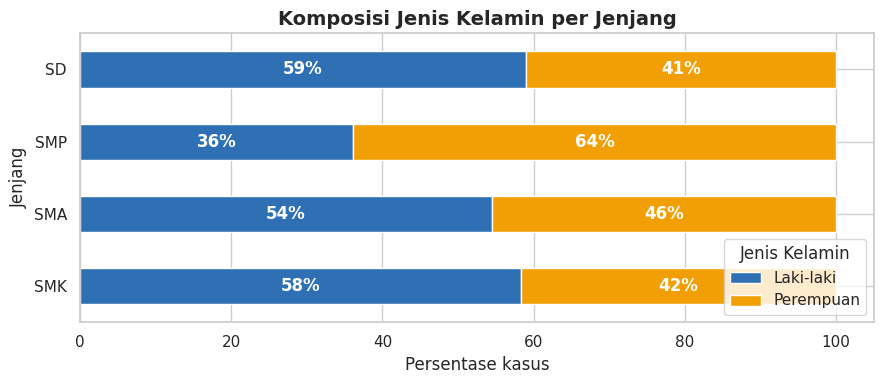

Jenis Kelamin,Laki-laki,Perempuan
Jenjang,,
SD,161,112
SMP,22,39
SMA,43,36
SMK,14,10


Jenis Kelamin,Laki-laki,Perempuan
Tahun,,
2021,46,56
2022,90,69
2023,49,42
2024,55,30


In [131]:
gender_jenjang = (dataset_all_df.pivot_table(index='Jenjang', columns='Jenis Kelamin', values='Jumlah', aggfunc='sum')
                  .loc[['SD', 'SMP', 'SMA', 'SMK']])
persen_gender = gender_jenjang.div(gender_jenjang.sum(axis=1), axis=0) * 100

ax = persen_gender.plot(kind='barh', stacked=True, figsize=(9, 4), color=['#2F6FB3', '#F29F05'])
for i, jenjang_nama in enumerate(persen_gender.index):
    l = persen_gender.loc[jenjang_nama, 'Laki-laki']
    p = persen_gender.loc[jenjang_nama, 'Perempuan']
    ax.text(l / 2, i, f"{l:.0f}%", ha='center', va='center', color='white', fontweight='bold')
    ax.text(l + p / 2, i, f"{p:.0f}%", ha='center', va='center', color='white', fontweight='bold')
ax.invert_yaxis()
ax.set_xlabel('Persentase kasus')
ax.set_title('Komposisi Jenis Kelamin per Jenjang', fontsize=14, fontweight='bold')
plt.legend(title='Jenis Kelamin', loc='lower right')
plt.tight_layout()
plt.show()

display(gender_jenjang)
gender_tahun = dataset_all_df.pivot_table(index='Tahun', columns='Jenis Kelamin', values='Jumlah', aggfunc='sum')
display(gender_tahun)

**Insight:** Polanya berbeda antar jenjang. Di **SD, anak laki-laki lebih banyak (59%)**, sedangkan di **SMP justru anak perempuan yang dominan (64%)**. Pada 2024 anak laki-laki mencapai 65% dari seluruh kasus (55 dari 85). Ini menunjukkan program pencegahan sebaiknya tidak seragam: pendekatan di SD dan SMP perlu dibedakan.

### E4: Pada kelas berapa anak paling rawan putus sekolah?
Data `Tingkat` memungkinkan kita melihat kelas mana yang paling banyak kehilangan siswa di SMP, SMA, dan SMK.

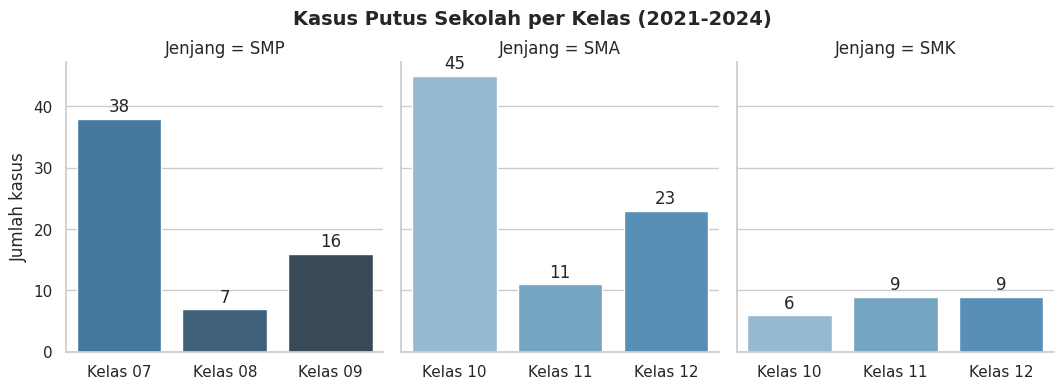

Kelas,Kelas 07,Kelas 08,Kelas 09,Kelas 10,Kelas 11,Kelas 12
Jenjang,,,,,,
SMA,NaN,NaN,NaN,57.0,13.9,29.1
SMK,NaN,NaN,NaN,25.0,37.5,37.5
SMP,62.3,11.5,26.2,NaN,NaN,NaN


In [132]:
kelas_df = (dataset_all_df[dataset_all_df['Kelas'] != 'Unknown']
            .groupby(['Jenjang', 'Kelas'])['Jumlah'].sum().reset_index())
kelas_df['Persen dalam jenjang'] = (kelas_df['Jumlah'] / kelas_df.groupby('Jenjang')['Jumlah'].transform('sum') * 100).round(1)

g = sns.catplot(data=kelas_df, x='Kelas', y='Jumlah', col='Jenjang', col_order=['SMP', 'SMA', 'SMK'],
                kind='bar', hue='Kelas', palette='Blues_d', legend=False, sharex=False, height=4, aspect=0.9)
for ax in g.axes.flat:
    for wadah in ax.containers:
        ax.bar_label(wadah, padding=2)
g.set_axis_labels('', 'Jumlah kasus')
g.figure.suptitle('Kasus Putus Sekolah per Kelas (2021-2024)', fontsize=14, fontweight='bold', y=1.03)
plt.show()

display(kelas_df.pivot(index='Jenjang', columns='Kelas', values='Persen dalam jenjang'))

**Insight:** Kerawanan terpusat pada **titik peralihan jenjang**: **kelas 7 menyumbang 62% kasus SMP** (38 dari 61) dan **kelas 10 menyumbang 57% kasus SMA** (45 dari 79), yaitu tepat setelah anak berpindah dari SD ke SMP dan dari SMP ke SMA. Pada SMK, kasus lebih merata di kelas 11 dan 12 (masing-masing 38%).

### E5: Seberapa terkonsentrasi kasusnya, dan kecamatan mana yang perlu diprioritaskan?

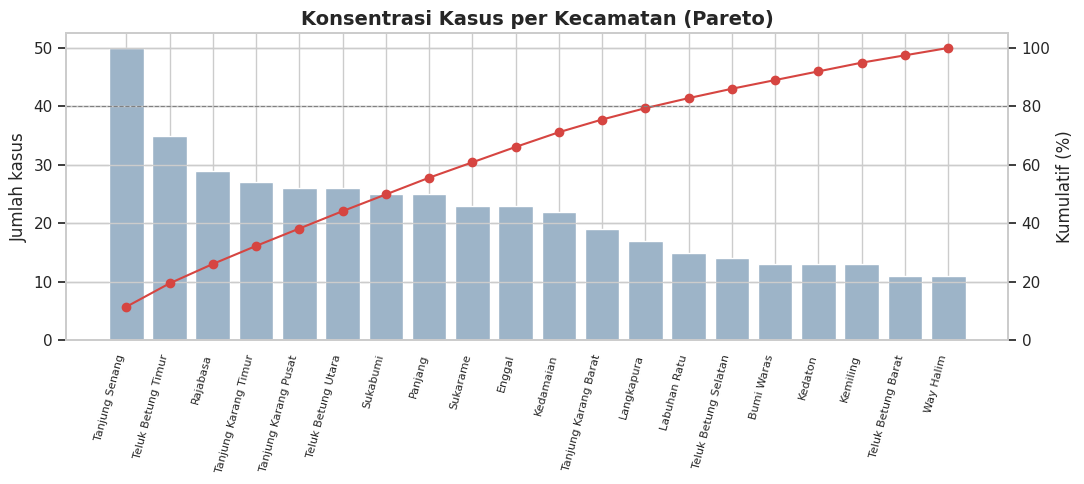

8 dari 20 kecamatan menyumbang 50% kasus; 14 kecamatan menyumbang 80% kasus.

Jumlah kecamatan per status prioritas:
Prioritas
Terkendali    15
Waspada        3
Pantau         2
Name: count, dtype: int64


Tahun,2023,2024,Perubahan 2024 vs 2023,Prioritas
Kecamatan,,,,
Teluk Betung Timur,4,23,19,Waspada
Sukabumi,1,8,7,Waspada
Tanjung Senang,8,6,-2,Pantau
Way Halim,0,6,6,Waspada
Panjang,9,5,-4,Pantau


In [133]:
# Kurva Pareto: berapa kecamatan yang menyumbang separuh dan 80% kasus?
pareto = kec_tahun['Total'].sort_values(ascending=False)
pareto_kum = pareto.cumsum() / pareto.sum() * 100

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(range(1, len(pareto) + 1), pareto.values, color='#9DB4C8')
ax1.set_xticks(range(1, len(pareto) + 1))
ax1.set_xticklabels(pareto.index, rotation=75, ha='right', fontsize=8)
ax1.set_ylabel('Jumlah kasus')
ax2 = ax1.twinx()
ax2.plot(range(1, len(pareto) + 1), pareto_kum.values, color='#D64541', marker='o')
ax2.axhline(80, color='gray', linestyle='--', linewidth=0.8)
ax2.set_ylabel('Kumulatif (%)')
ax2.set_ylim(0, 105)
plt.title('Konsentrasi Kasus per Kecamatan (Pareto)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

n50 = int((pareto_kum < 50).sum() + 1)
n80 = int((pareto_kum < 80).sum() + 1)
print(f"{n50} dari {len(pareto)} kecamatan menyumbang 50% kasus; {n80} kecamatan menyumbang 80% kasus.")

# Status prioritas kecamatan (aturan sederhana & transparan, berbasis kondisi terbaru)
def tentukan_prioritas(baris):
    if baris[2024] > baris[2023] and baris[2024] >= 6:
        return 'Waspada'      # kasus naik dan sudah cukup besar
    if baris[2024] >= 5:
        return 'Pantau'       # kasus tinggi tetapi tidak naik
    return 'Terkendali'

status_kec = kec_tahun.copy()
status_kec['Perubahan 2024 vs 2023'] = status_kec[2024] - status_kec[2023]
status_kec['Arah'] = np.where(status_kec['Perubahan 2024 vs 2023'] > 0, 'Naik',
                      np.where(status_kec['Perubahan 2024 vs 2023'] < 0, 'Turun', 'Tetap'))
status_kec['Prioritas'] = status_kec.apply(tentukan_prioritas, axis=1)
status_kec = status_kec.sort_values([2024, 'Total'], ascending=False)

print("\nJumlah kecamatan per status prioritas:")
print(status_kec['Prioritas'].value_counts())
display(status_kec[status_kec['Prioritas'] != 'Terkendali'][[2023, 2024, 'Perubahan 2024 vs 2023', 'Prioritas']])

**Insight:** Kasus cukup terkonsentrasi: **8 dari 20 kecamatan menyumbang 50% kasus**, dan 14 kecamatan menyumbang 80%. Berdasarkan kondisi terbaru (2024), kecamatan dikelompokkan menjadi:
- **Waspada** (kasus naik dan sudah ≥ 6): Teluk Betung Timur, Sukabumi, Way Halim
- **Pantau** (kasus ≥ 5 tetapi tidak naik): Tanjung Senang, Panjang
- **Terkendali**: 15 kecamatan lainnya

Aturan ambang (≥ 6 dan ≥ 5) bersifat kebijakan sederhana yang dapat disesuaikan.

## 5. Pemodelan Data (Data Modeling)
### Pertanyaan 5: Bagaimana proyeksi tren total anak putus sekolah di masa depan (tahun 2025) berdasarkan data historis?
Untuk menjawab pertanyaan ini, kita akan menggunakan algoritma *Machine Learning* sederhana yaitu **Linear Regression**. Model ini akan mempelajari pola garis lurus dari data tahun 2021-2024 dan memproyeksikan estimasi angkanya untuk tahun 2025.

Karena data historis hanya terdiri dari **4 titik tahunan**, evaluasi model dilengkapi dengan *Leave-One-Out* (membandingkan dengan tebakan rata-rata) dan rentang ketidakpastian 95% agar hasil proyeksi tidak terlalu dipercaya.

--- Evaluasi Model Linear Regression ---
Slope (perubahan per tahun) : -11.90 anak/tahun
MAE  : 21.90
RMSE : 26.18
R2   : 0.21

MAE Leave-One-Out (model regresi)  : 46.29
MAE Leave-One-Out (tebakan rata-rata): 33.17

--- Hasil Proyeksi Anak Putus Sekolah ---
Tahun 2021 (Historis): 127 anak
Tahun 2022 (Historis): 115 anak
Tahun 2023 (Historis): 103 anak
Tahun 2024 (Historis): 91 anak
Tahun 2025 (Proyeksi): 80 anak

Rentang ketidakpastian 95% untuk 2025: 0 - 331 anak


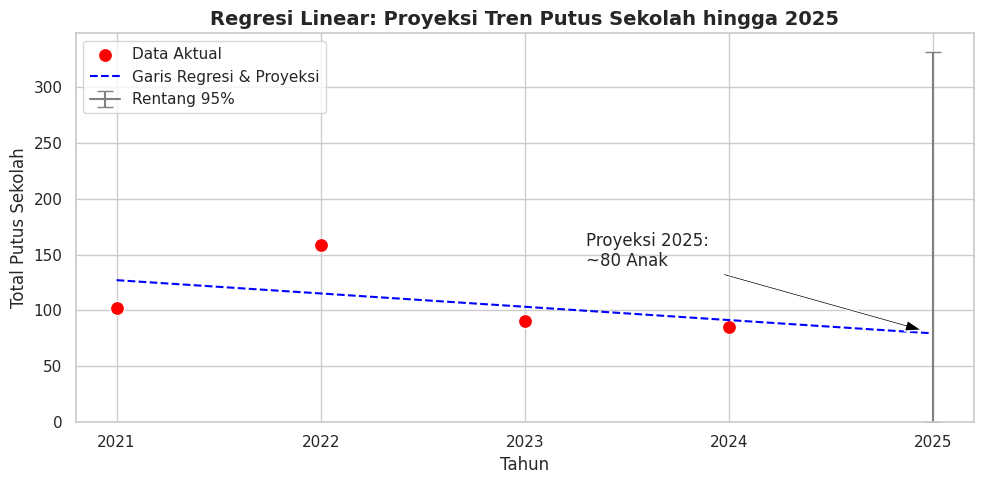

In [134]:
# ==========================================
# 5. PREDIKSI / PROYEKSI TAHUN 2025
# ==========================================

# Menyiapkan data agregat tahunan untuk regresi linier
df_regresi = dataset_all_df.groupby('Tahun')['Jumlah'].sum().reset_index()

X = df_regresi[['Tahun']]
y = df_regresi['Jumlah']

# Melatih model Linear Regression
model = LinearRegression()
model.fit(X, y)

# Melakukan prediksi untuk tahun historis dan proyeksi 2025
tahun_prediksi = pd.DataFrame({'Tahun': [2021, 2022, 2023, 2024, 2025]})
prediksi_jumlah = model.predict(tahun_prediksi)

# Evaluasi performa model pada data historis
y_pred_historis = model.predict(X)
mae = mean_absolute_error(y, y_pred_historis)
mse = mean_squared_error(y, y_pred_historis)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred_historis)

print("--- Evaluasi Model Linear Regression ---")
print(f"Slope (perubahan per tahun) : {model.coef_[0]:.2f} anak/tahun")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R2   : {r2:.2f}")

# Evaluasi tambahan untuk data kecil: Leave-One-Out (latih tanpa 1 tahun, lalu uji pada tahun tersebut)
X_arr, y_arr = X.values, y.values
galat_model, galat_rata2 = [], []
for i in range(len(y_arr)):
    sisa = [j for j in range(len(y_arr)) if j != i]
    m_loo = LinearRegression().fit(X_arr[sisa], y_arr[sisa])
    galat_model.append(abs(m_loo.predict(X_arr[[i]])[0] - y_arr[i]))
    galat_rata2.append(abs(y_arr[sisa].mean() - y_arr[i]))
mae_loo, mae_baseline = np.mean(galat_model), np.mean(galat_rata2)
print(f"\nMAE Leave-One-Out (model regresi)  : {mae_loo:.2f}")
print(f"MAE Leave-One-Out (tebakan rata-rata): {mae_baseline:.2f}")

print("\n--- Hasil Proyeksi Anak Putus Sekolah ---")
for t, p in zip(tahun_prediksi['Tahun'], prediksi_jumlah):
    status = "Proyeksi" if t > 2024 else "Historis"
    print(f"Tahun {t} ({status}): {int(round(p))} anak")

# Rentang ketidakpastian (interval prediksi 95%) untuk 2025
n = len(y_arr)
s_galat = np.sqrt(np.sum((y_arr - y_pred_historis) ** 2) / (n - 2))
x_rata = X_arr.mean()
se_prediksi = s_galat * np.sqrt(1 + 1/n + (2025 - x_rata) ** 2 / np.sum((X_arr.flatten() - x_rata) ** 2))
t_kritis = stats.t.ppf(0.975, df=n - 2)
proyeksi_2025 = prediksi_jumlah[-1]
batas_bawah = max(0, proyeksi_2025 - t_kritis * se_prediksi)
batas_atas = proyeksi_2025 + t_kritis * se_prediksi
print(f"\nRentang ketidakpastian 95% untuk 2025: {batas_bawah:.0f} - {batas_atas:.0f} anak")

# Visualisasi Hasil Regresi
df_reg = df_regresi
X_pred = tahun_prediksi
y_pred = prediksi_jumlah

plt.figure(figsize=(10, 5))
sns.scatterplot(x=df_reg['Tahun'], y=df_reg['Jumlah'], color='red', s=100, label='Data Aktual')
sns.lineplot(x=X_pred['Tahun'], y=y_pred, color='blue', linestyle='--', label='Garis Regresi & Proyeksi')
plt.errorbar(2025, y_pred[-1], yerr=[[y_pred[-1] - batas_bawah], [batas_atas - y_pred[-1]]],
             color='gray', capsize=6, label='Rentang 95%')

# Anotasi titik untuk Prediksi 2025
pred_2025_value = int(round(y_pred[-1]))
plt.annotate(f'Proyeksi 2025:\n~{pred_2025_value} Anak',
             xy=(2025, y_pred[-1]), xytext=(2023.3, y_pred[-1] + 60),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8))

plt.title('Regresi Linear: Proyeksi Tren Putus Sekolah hingga 2025', fontsize=14, fontweight='bold')
plt.xlabel('Tahun')
plt.ylabel('Total Putus Sekolah')
plt.xticks(X_pred['Tahun'])
plt.ylim(0, None)
plt.legend()
plt.tight_layout()
plt.show()

**Cara membaca hasil:**
- Arah garis regresi menurun, tetapi **R² rendah** dan **rentang ketidakpastian 95% sangat lebar**, karena hanya ada 4 titik data dan tahun 2022 merupakan lonjakan tajam.
- Pada uji *Leave-One-Out*, model regresi **tidak lebih akurat daripada tebakan rata-rata** (MAE regresi lebih besar dari MAE baseline). Artinya data belum cukup untuk membuktikan tren penurunan yang stabil.
- Karena itu, proyeksi 2025 sebaiknya dipahami sebagai **perkiraan kasar arah tren, bukan target pasti**.

### Ekspor Data untuk Dashboard (Looker Studio)
Selain `dataset_all_clean.csv` (sumber data utama), kita menyiapkan tiga file ringkasan yang sudah dihitung di sini, sehingga di Looker Studio cukup *drag and drop* tanpa rumus: **KPI** (untuk scorecard; nama kolomnya sudah berupa label kartu), **status kecamatan** (untuk tabel prioritas), dan **tren + proyeksi**.

In [135]:
os.makedirs('output_looker', exist_ok=True)

# File 1: KPI ringkas (satu baris) -> sumber scorecard di Looker Studio
kasus_2023 = int(tren_tahunan.loc[tren_tahunan['Tahun'] == 2023, 'Jumlah'].iloc[0])
kasus_2024 = int(tren_tahunan.loc[tren_tahunan['Tahun'] == 2024, 'Jumlah'].iloc[0])
sd_2024 = int(dataset_all_df[(dataset_all_df['Jenjang'] == 'SD') & (dataset_all_df['Tahun'] == 2024)]['Jumlah'].sum())

kpi = pd.DataFrame([{
    # 5 kolom pertama = isi scorecard. NAMA KOLOM = LABEL yang tampil di kartu (tidak perlu diganti di Looker Studio)
    'Total kasus 2021-2024'                  : int(dataset_all_df['Jumlah'].sum()),
    'Perubahan kasus 2024 vs 2023'          : round(kasus_2024 / kasus_2023 - 1, 4),
    'Porsi SD dari seluruh kasus 2024'      : round(sd_2024 / kasus_2024, 4),
    f'Kasus di {hotspot_2024} 2024'         : int(kec_tahun[2024].max()),
    'Proyeksi 2025 (indikatif)'             : int(round(proyeksi_2025)),
    # kolom pendukung
    'Kasus 2023'                            : kasus_2023,
    'Kasus 2024'                            : kasus_2024,
    'Penurunan dari puncak'                 : round(1 - kasus_2024 / tren_tahunan['Jumlah'].max(), 4),
    'Porsi hotspot 2024'                    : round(kec_tahun[2024].max() / kasus_2024, 4),
    'Kecamatan membaik'                     : int((kec_tahun[2024] < kec_tahun[2023]).sum()),
    'Total kecamatan'                       : int(len(kec_tahun)),
    'Proyeksi batas bawah'                  : int(round(batas_bawah)),
    'Proyeksi batas atas'                   : int(round(batas_atas)),
}])
kpi.to_csv('output_looker/dashboard_kpi.csv', index=False)

# File 2: Status kecamatan (seluruh 20 kecamatan) -> tabel prioritas
kecamatan_status = status_kec.reset_index()
kecamatan_status = kecamatan_status.rename(columns={2021: 'Kasus 2021', 2022: 'Kasus 2022', 2023: 'Kasus 2023', 2024: 'Kasus 2024', 'Total': 'Total Kasus'})
kecamatan_status = kecamatan_status[['Kecamatan', 'Kasus 2021', 'Kasus 2022', 'Kasus 2023', 'Kasus 2024',
                                     'Total Kasus', 'Perubahan 2024 vs 2023', 'Arah', 'Prioritas']]
kecamatan_status.to_csv('output_looker/kecamatan_status.csv', index=False)

# File 3: Tren tahunan + proyeksi 2025
tren_proyeksi = tren_tahunan.copy()
tren_proyeksi['Tipe'] = 'Aktual'
tren_proyeksi['Batas Bawah'] = tren_proyeksi['Jumlah']
tren_proyeksi['Batas Atas'] = tren_proyeksi['Jumlah']
baris_proyeksi = pd.DataFrame([{'Tahun': 2025, 'Jumlah': int(round(proyeksi_2025)), 'Tipe': 'Proyeksi',
                                'Batas Bawah': int(round(batas_bawah)), 'Batas Atas': int(round(batas_atas))}])
tren_proyeksi = pd.concat([tren_proyeksi, baris_proyeksi], ignore_index=True)
tren_proyeksi.to_csv('output_looker/tren_dan_proyeksi.csv', index=False)

# Cek konsistensi seluruh file
assert (dataset_all_df['Jumlah'].sum() == kecamatan_status['Total Kasus'].sum() == kpi.loc[0, 'Total kasus 2021-2024']
        == tren_proyeksi[tren_proyeksi['Tipe'] == 'Aktual']['Jumlah'].sum())
print("Semua file konsisten. Total kasus =", dataset_all_df['Jumlah'].sum())
display(kpi.T.rename(columns={0: 'Nilai'}))

# Di Google Colab: unduh file hasil
try:
    from google.colab import files
    for f in [output_filename, 'output_looker/dashboard_kpi.csv', 'output_looker/kecamatan_status.csv', 'output_looker/tren_dan_proyeksi.csv']:
        files.download(f)
except ImportError:
    print("Bukan di Colab: file tersimpan di folder kerja ('dataset_all_clean.csv' dan folder 'output_looker/').")

Semua file konsisten. Total kasus = 437


,Nilai
Total kasus 2021-2024,437.0000
Perubahan kasus 2024 vs 2023,-0.0659
Porsi SD dari seluruh kasus 2024,0.8824
Kasus di Teluk Betung Timur 2024,23.0000
Proyeksi 2025 (indikatif),80.0000
Kasus 2023,91.0000
Kasus 2024,85.0000
Penurunan dari puncak,0.4654
Porsi hotspot 2024,0.2706
Kecamatan membaik,13.0000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Kesimpulan
- **Tren:** Jumlah anak putus sekolah mencapai puncak pada **2022 (159 anak)**, lalu turun menjadi 91 (2023) dan **85 (2024)**. Penurunan dari puncak sebesar **47%**, dan **6,6%** dibanding 2023. Garis regresi melandai ke bawah, namun polanya belum stabil.
- **Jenjang:** Dari total **437 anak**, jenjang **SD** menyumbang paling banyak (**273 kasus, 62,5%**), diikuti SMA (79), SMP (61), dan SMK (24). Pada 2024, SD menyumbang **88%** seluruh kasus. Pada jenjang SD, kasus lebih banyak terjadi di sekolah Negeri (243) dibanding Swasta (30).
- **Hotspot kumulatif vs terbaru:** Tanjung Senang tertinggi secara kumulatif (50 kasus), tetapi **31 di antaranya terjadi pada 2022** (lonjakan satu tahun, terutama SMA) dan sudah turun menjadi 6 pada 2024. Hotspot terbaru adalah **Teluk Betung Timur: 23 kasus pada 2024 (27% dari seluruh kasus tahun itu)**, naik dari 4 pada 2023.
- **Kenaikan SD bersifat lokal:** kenaikan bersih SD pada 2024 (+19) sama dengan kenaikan di Teluk Betung Timur (+19). Tanpa kecamatan itu, kasus SD tidak berubah. Secara keseluruhan **13 dari 20 kecamatan membaik**, 4 tetap, dan 3 naik (Teluk Betung Timur, Sukabumi, Way Halim).
- **Profil anak:** Di SD, 59% kasus adalah anak laki-laki, sedangkan di SMP 64% adalah anak perempuan. Kerawanan terpusat pada **titik peralihan jenjang**: kelas 7 (62% kasus SMP) dan kelas 10 (57% kasus SMA).
- **Konsentrasi:** 8 dari 20 kecamatan menyumbang 50% kasus.
- **Proyeksi:** Model regresi linear mengestimasikan sekitar **80 anak** pada 2025, dengan rentang ketidakpastian 95% yang sangat lebar (0-331), $R^2$ 0.21, MAE 21.90, RMSE 26.18. Pada uji *Leave-One-Out* model ini tidak mengungguli tebakan rata-rata, sehingga hasilnya hanya indikatif.
- **Kualitas Data:** Dataset mentah memuat baris `Total` yang bercampur dengan rincian serta duplikat pada SMK, sehingga penjumlahan langsung menghasilkan 922 (terhitung ganda). Setelah dibersihkan, total yang benar adalah 437 anak.

## Rekomendasi
- **Sistem peringatan dini per kecamatan:** Angka total yang turun dapat menyembunyikan lonjakan lokal (Tanjung Senang 2022, Teluk Betung Timur 2024). Pantau kasus per kecamatan secara berkala dan beri status **Waspada** bila naik tajam. Saat ini yang berstatus Waspada: Teluk Betung Timur, Sukabumi, dan Way Halim.
- **Telusuri penyebab di Teluk Betung Timur:** Lakukan verifikasi lapangan atas 23 kasus SD pada 2024 (apakah lonjakan nyata, perubahan pencatatan, atau faktor lokal) sebelum menentukan bentuk intervensi.
- **Program pendampingan masa transisi:** Fokuskan dukungan (bantuan biaya, pendampingan, pemantauan kehadiran) pada anak yang baru masuk kelas 7 dan kelas 10, yang merupakan titik paling rawan.
- **Pendekatan berbeda menurut jenjang dan gender:** Kaji faktor penyebab pada anak laki-laki di SD dan anak perempuan di SMP, karena polanya berlawanan.
- **Pelajari kecamatan yang membaik:** Contohnya Kedamaian (16 kasus pada 2021 menjadi 2 pada 2024) dan Labuhan Ratu (11 menjadi 1), untuk direplikasi ke wilayah lain.
- **Perbaikan data:** Tambahkan data jumlah siswa agar risiko dapat dihitung sebagai rasio, hindari baris `Total` yang bercampur dengan rincian dan duplikasi data SMK, serta gunakan data semesteran agar model proyeksi lebih andal.